## 1. Imports and reproducibility

In [2]:
import os
import shutil
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.special import logsumexp
from scipy.stats import multivariate_normal
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, confusion_matrix, classification_report
)
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)

RESULTS_DIR = Path("mle_vs_bayesian_results")
RESULTS_DIR.mkdir(exist_ok=True)

print("Libraries loaded.")
print("Results directory:", RESULTS_DIR.resolve())

Libraries loaded.
Results directory: /content/mle_vs_bayesian_results


In [3]:
def generate_data(n_samples, rng, means=None, covariance=None, class_probs=(0.5, 0.5)):
    if means is None:
        means = np.array([[-1.0, -0.8], [1.0, 0.8]])
    if covariance is None:
        covariance = np.array([[1.0, 0.25], [0.25, 1.0]])

    y = rng.choice(2, size=n_samples, p=class_probs)
    X = np.empty((n_samples, 2), dtype=float)
    for k in (0, 1):
        idx = np.where(y == k)[0]
        if len(idx):
            X[idx] = rng.multivariate_normal(means[k], covariance, size=len(idx))
    return X, y

TRUE_MEANS = np.array([[-1.0, -0.8], [1.0, 0.8]])
KNOWN_COV = np.array([[1.0, 0.25], [0.25, 1.0]])
CLASS_PROBS = (0.5, 0.5)

data_rng = np.random.default_rng(SEED)
X_train, y_train = generate_data(120, data_rng, TRUE_MEANS, KNOWN_COV, CLASS_PROBS)
X_test, y_test = generate_data(3000, data_rng, TRUE_MEANS, KNOWN_COV, CLASS_PROBS)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Training class counts:", np.bincount(y_train, minlength=2))
print("Test class counts:", np.bincount(y_test, minlength=2))

Training shape: (120, 2)
Test shape: (3000, 2)
Training class counts: [62 58]
Test class counts: [1524 1476]


### Visualize the simulated data

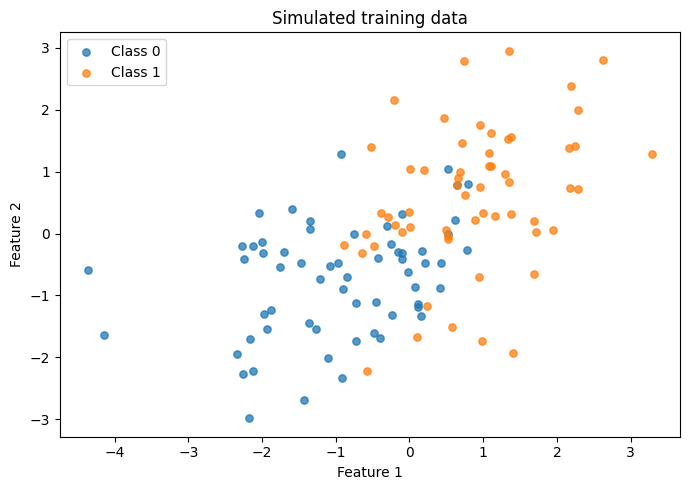

In [4]:
plt.figure(figsize=(7, 5))
for k, label in [(0, "Class 0"), (1, "Class 1")]:
    plt.scatter(X_train[y_train == k, 0], X_train[y_train == k, 1],
                alpha=0.75, s=28, label=label)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Simulated training data")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "01_simulated_training_data.png", dpi=180)
plt.show()

In [5]:
def fit_mle(X, y, covariance=KNOWN_COV):
    classes = np.array([0, 1])
    means, priors, counts = [], [], []
    for k in classes:
        Xk = X[y == k]
        if len(Xk) == 0:
            raise ValueError(f"Training data contains no examples of class {k}.")
        means.append(Xk.mean(axis=0))
        counts.append(len(Xk))
    counts = np.asarray(counts, dtype=float)
    means = np.asarray(means)
    priors = counts / counts.sum()
    return {
        "classes": classes,
        "means": means,
        "priors": priors,
        "predictive_covariances": np.repeat(covariance[None, :, :], 2, axis=0),
        "counts": counts.astype(int),
        "method": "MLE"
    }


def fit_bayesian(X, y, covariance=KNOWN_COV, prior_mean=None,
                 prior_variance=4.0, dirichlet_alpha=1.0):
    classes = np.array([0, 1])
    if prior_mean is None:
        prior_mean = np.zeros(X.shape[1])
    prior_mean = np.asarray(prior_mean, dtype=float)

    means, pred_covs, counts = [], [], []
    for k in classes:
        Xk = X[y == k]
        n_k = len(Xk)
        if n_k == 0:
            # With zero observations, the posterior remains the prior.
            xbar = prior_mean.copy()
        else:
            xbar = Xk.mean(axis=0)

        # Normal prior N(prior_mean, prior_variance * I) and known
        # observation covariance sigma^2 I are exact conjugates only
        # when covariance is isotropic. This implementation uses the
        # general matrix form for the posterior with known covariance.
        prior_cov = prior_variance * np.eye(X.shape[1])
        prior_precision = np.linalg.inv(prior_cov)
        obs_precision = np.linalg.inv(covariance)
        post_cov = np.linalg.inv(prior_precision + n_k * obs_precision)
        post_mean = post_cov @ (
            prior_precision @ prior_mean +
            (n_k * obs_precision @ xbar if n_k > 0 else np.zeros_like(prior_mean))
        )
        predictive_cov = covariance + post_cov

        means.append(post_mean)
        pred_covs.append(predictive_cov)
        counts.append(n_k)

    counts = np.asarray(counts, dtype=float)
    priors = (counts + dirichlet_alpha) / (counts.sum() + len(classes) * dirichlet_alpha)
    return {
        "classes": classes,
        "means": np.asarray(means),
        "priors": priors,
        "predictive_covariances": np.asarray(pred_covs),
        "counts": counts.astype(int),
        "method": "Bayesian"
    }


def predict_proba(model, X):
    log_scores = []
    for i, k in enumerate(model["classes"]):
        log_density = multivariate_normal.logpdf(
            X,
            mean=model["means"][i],
            cov=model["predictive_covariances"][i],
            allow_singular=False
        )
        log_scores.append(log_density + np.log(model["priors"][i]))
    log_scores = np.vstack(log_scores).T
    log_norm = logsumexp(log_scores, axis=1, keepdims=True)
    return np.exp(log_scores - log_norm)


def predict(model, X):
    probabilities = predict_proba(model, X)
    return model["classes"][np.argmax(probabilities, axis=1)]

In [6]:
mle_model = fit_mle(X_train, y_train, KNOWN_COV)
bayes_model = fit_bayesian(
    X_train, y_train, KNOWN_COV,
    prior_mean=np.zeros(2),
    prior_variance=4.0,
    dirichlet_alpha=1.0
)

def evaluate_model(model, X, y):
    proba = predict_proba(model, X)
    pred = model["classes"][np.argmax(proba, axis=1)]
    return {
        "Model": model["method"],
        "Accuracy": accuracy_score(y, pred),
        "Precision (class 1)": precision_score(y, pred, zero_division=0),
        "Recall (class 1)": recall_score(y, pred, zero_division=0),
        "F1-score (class 1)": f1_score(y, pred, zero_division=0),
        "Log loss": log_loss(y, proba, labels=[0, 1])
    }

main_metrics = pd.DataFrame([
    evaluate_model(mle_model, X_test, y_test),
    evaluate_model(bayes_model, X_test, y_test)
])
display(main_metrics.round(4))
main_metrics.to_csv(RESULTS_DIR / "main_model_metrics.csv", index=False)

for model in [mle_model, bayes_model]:
    print("\n", model["method"], "classification report")
    print(classification_report(y_test, predict(model, X_test), digits=4, zero_division=0))
    cm = confusion_matrix(y_test, predict(model, X_test), labels=[0, 1])
    print("Confusion matrix (rows=true class, columns=predicted class):\n", cm)

,Model,Accuracy,Precision (class 1),Recall (class 1),F1-score (class 1),Log loss
0,MLE,0.8693,0.8585,0.8794,0.8688,0.3029
1,Bayesian,0.8693,0.8585,0.8794,0.8688,0.3034



 MLE classification report
              precision    recall  f1-score   support

           0     0.8804    0.8596    0.8699      1524
           1     0.8585    0.8794    0.8688      1476

    accuracy                         0.8693      3000
   macro avg     0.8694    0.8695    0.8693      3000
weighted avg     0.8696    0.8693    0.8693      3000

Confusion matrix (rows=true class, columns=predicted class):
 [[1310  214]
 [ 178 1298]]

 Bayesian classification report
              precision    recall  f1-score   support

           0     0.8804    0.8596    0.8699      1524
           1     0.8585    0.8794    0.8688      1476

    accuracy                         0.8693      3000
   macro avg     0.8694    0.8695    0.8693      3000
weighted avg     0.8696    0.8693    0.8693      3000

Confusion matrix (rows=true class, columns=predicted class):
 [[1310  214]
 [ 178 1298]]


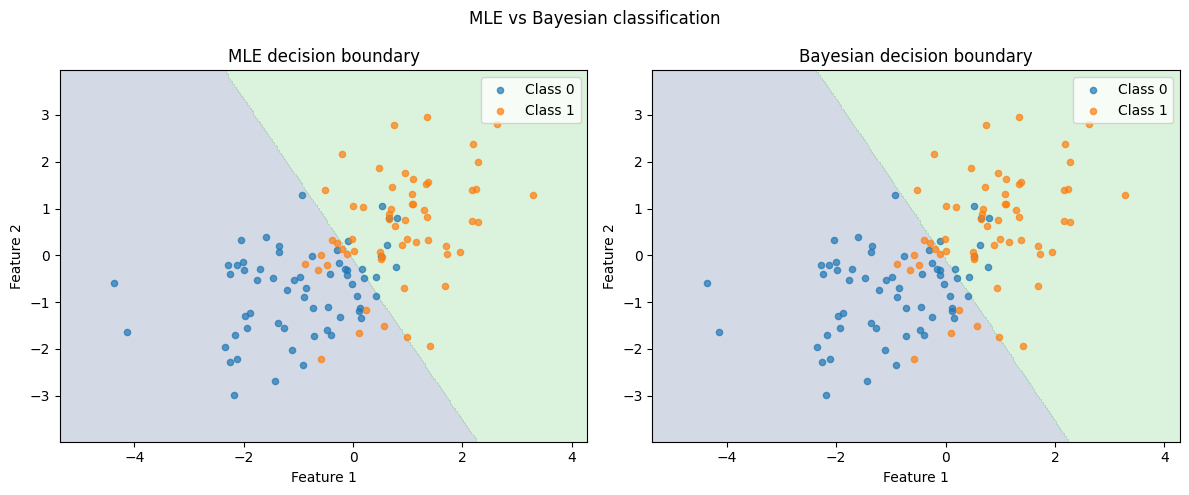

In [7]:
def plot_decision_boundaries(models, X, y, filename, title):
    x_min, x_max = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
    y_min, y_max = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]

    fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 5), squeeze=False)
    for ax, model in zip(axes[0], models):
        zz = predict(model, grid).reshape(xx.shape)
        ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], alpha=0.22)
        for k, label in [(0, "Class 0"), (1, "Class 1")]:
            ax.scatter(X[y == k, 0], X[y == k, 1], s=20, alpha=0.7, label=label)
        ax.set_title(f"{model['method']} decision boundary")
        ax.set_xlabel("Feature 1")
        ax.set_ylabel("Feature 2")
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()

plot_decision_boundaries(
    [mle_model, bayes_model], X_train, y_train,
    "02_decision_boundaries_main.png",
    "MLE vs Bayesian classification"
)

In [8]:
N_REPEATS = 20
TRAIN_SIZES = [20, 50, 100, 250, 500]
EXPERIMENT_TEST_N = 3000
experiment_rows = []

for n_train in TRAIN_SIZES:
    for rep in range(N_REPEATS):
        local_rng = np.random.default_rng(10000 + n_train * 100 + rep)
        Xtr, ytr = generate_data(n_train, local_rng, TRUE_MEANS, KNOWN_COV, CLASS_PROBS)
        Xte, yte = generate_data(EXPERIMENT_TEST_N, local_rng, TRUE_MEANS, KNOWN_COV, CLASS_PROBS)

        models = [
            fit_mle(Xtr, ytr, KNOWN_COV),
            fit_bayesian(Xtr, ytr, KNOWN_COV, prior_mean=np.zeros(2),
                         prior_variance=4.0, dirichlet_alpha=1.0)
        ]
        for model in models:
            row = evaluate_model(model, Xte, yte)
            row["Training size"] = n_train
            row["Repetition"] = rep + 1
            experiment_rows.append(row)

size_results = pd.DataFrame(experiment_rows)
size_results.to_csv(RESULTS_DIR / "training_size_experiment_all_runs.csv", index=False)

summary = (size_results.groupby(["Training size", "Model"])
           .agg(**{
               "Accuracy mean": ("Accuracy", "mean"),
               "Accuracy std": ("Accuracy", "std"),
               "F1 mean": ("F1-score (class 1)", "mean"),
               "F1 std": ("F1-score (class 1)", "std"),
               "Log loss mean": ("Log loss", "mean"),
               "Log loss std": ("Log loss", "std")
           }).reset_index())
summary.to_csv(RESULTS_DIR / "training_size_experiment_summary.csv", index=False)
display(summary.round(4))

,Training size,Model,Accuracy mean,Accuracy std,F1 mean,F1 std,Log loss mean,Log loss std
0,20,Bayesian,0.8508,0.0272,0.8500,0.0255,0.3399,0.0484
1,20,MLE,0.8507,0.0272,0.8499,0.0257,0.3458,0.0556
2,50,Bayesian,0.8726,0.0107,0.8717,0.0131,0.2988,0.0183
3,50,MLE,0.8725,0.0107,0.8717,0.0131,0.2984,0.0188
4,100,Bayesian,0.8738,0.0085,0.8727,0.0095,0.2946,0.0130
5,100,MLE,0.8738,0.0085,0.8727,0.0095,0.2945,0.0133
6,250,Bayesian,0.8731,0.0049,0.8730,0.0054,0.2971,0.0069
7,250,MLE,0.8731,0.0050,0.8730,0.0055,0.2971,0.0070
8,500,Bayesian,0.8724,0.0070,0.8725,0.0076,0.2951,0.0113
9,500,MLE,0.8724,0.0070,0.8725,0.0076,0.2951,0.0113


### Plot performance against training-set size

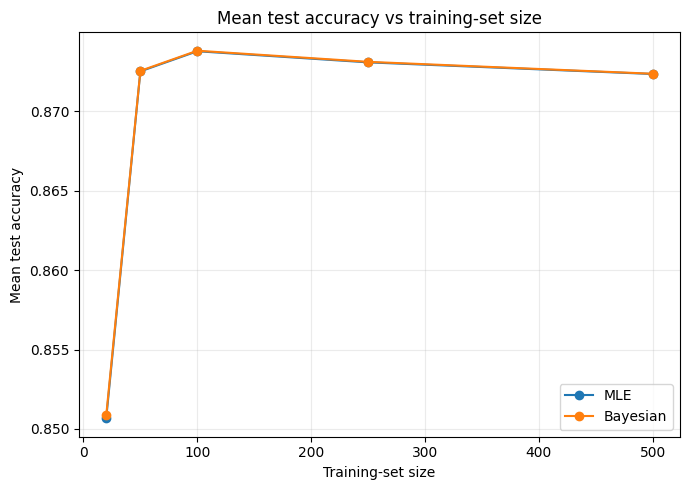

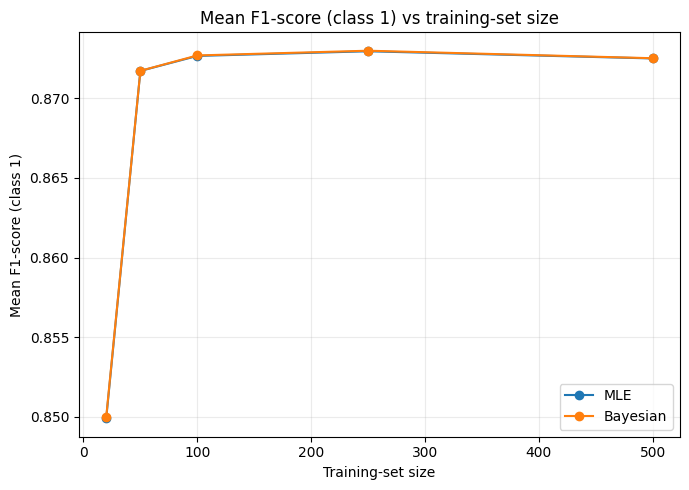

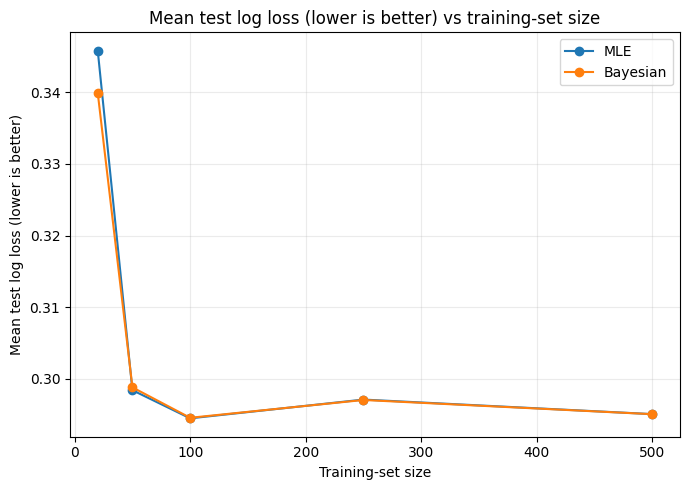

In [9]:
for metric, ylabel, filename in [
    ("Accuracy mean", "Mean test accuracy", "03_accuracy_by_training_size.png"),
    ("F1 mean", "Mean F1-score (class 1)", "04_f1_by_training_size.png"),
    ("Log loss mean", "Mean test log loss (lower is better)", "05_logloss_by_training_size.png")
]:
    plt.figure(figsize=(7, 5))
    for model_name in ["MLE", "Bayesian"]:
        subset = summary[summary["Model"] == model_name]
        plt.plot(subset["Training size"], subset[metric], marker="o", label=model_name)
    plt.xlabel("Training-set size")
    plt.ylabel(ylabel)
    plt.title(f"{ylabel} vs training-set size")
    plt.legend()
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / filename, dpi=180)
    plt.show()

In [10]:
prior_rng = np.random.default_rng(2026)
X_small, y_small = generate_data(30, prior_rng, TRUE_MEANS, KNOWN_COV, CLASS_PROBS)
X_prior_test, y_prior_test = generate_data(5000, prior_rng, TRUE_MEANS, KNOWN_COV, CLASS_PROBS)

prior_rows = []
prior_models = [fit_mle(X_small, y_small, KNOWN_COV)]
for prior_var in [0.1, 0.5, 1.0, 4.0, 25.0, 100.0]:
    prior_models.append(
        fit_bayesian(X_small, y_small, KNOWN_COV, prior_mean=np.zeros(2),
                     prior_variance=prior_var, dirichlet_alpha=1.0)
    )
    prior_models[-1]["method"] = f"Bayesian (prior variance={prior_var})"

for model in prior_models:
    row = evaluate_model(model, X_prior_test, y_prior_test)
    row["Prior variance"] = np.nan if model["method"] == "MLE" else float(model["method"].split("=")[1].rstrip(")"))
    prior_rows.append(row)

prior_results = pd.DataFrame(prior_rows)
prior_results.to_csv(RESULTS_DIR / "prior_sensitivity_experiment.csv", index=False)
display(prior_results.round(4))

,Model,Accuracy,Precision (class 1),Recall (class 1),F1-score (class 1),Log loss,Prior variance
0,MLE,0.8694,0.8603,0.8858,0.8728,0.2975,NaN
1,Bayesian (prior variance=0.1),0.8668,0.8722,0.8632,0.8677,0.3297,0.1
2,Bayesian (prior variance=0.5),0.8688,0.8612,0.8830,0.8720,0.2981,0.5
3,Bayesian (prior variance=1.0),0.8688,0.8607,0.8838,0.8721,0.2967,1.0
4,Bayesian (prior variance=4.0),0.8696,0.8609,0.8854,0.8730,0.2963,4.0
5,Bayesian (prior variance=25.0),0.8696,0.8606,0.8858,0.8730,0.2964,25.0
6,Bayesian (prior variance=100.0),0.8698,0.8607,0.8862,0.8732,0.2964,100.0


In [11]:
parameter_rows = []
for model in [mle_model, bayes_model]:
    for i, k in enumerate(model["classes"]):
        parameter_rows.append({
            "Model": model["method"],
            "Class": int(k),
            "Estimated mean feature 1": model["means"][i, 0],
            "Estimated mean feature 2": model["means"][i, 1],
            "Estimated class prior": model["priors"][i],
            "Training count": int(model["counts"][i])
        })
parameter_table = pd.DataFrame(parameter_rows)
display(parameter_table.round(4))
parameter_table.to_csv(RESULTS_DIR / "estimated_parameters.csv", index=False)

,Model,Class,Estimated mean feature 1,Estimated mean feature 2,Estimated class prior,Training count
0,MLE,0,-0.9510,-0.7335,0.5167,62
1,MLE,1,0.8536,0.5781,0.4833,58
2,Bayesian,0,-0.9465,-0.7296,0.5164,62
3,Bayesian,1,0.8493,0.5747,0.4836,58


In [12]:
manifest = f'''
Project: MLE vs Bayesian Parameter Estimation
Random seed (main data): {SEED}
True class means: {TRUE_MEANS.tolist()}
Known covariance: {KNOWN_COV.tolist()}
Class probabilities: {CLASS_PROBS}
Bayesian prior mean: [0.0, 0.0]
Bayesian prior variance (main model): 4.0
Dirichlet alpha (main model): 1.0
Training-size repetitions: {N_REPEATS}
Training sizes: {TRAIN_SIZES}
Test-set size per repetition: {EXPERIMENT_TEST_N}
'''
(RESULTS_DIR / "run_manifest.txt").write_text(manifest, encoding="utf-8")

zip_output = Path("MLE_vs_Bayesian_Results.zip")
if zip_output.exists():
    zip_output.unlink()
with zipfile.ZipFile(zip_output, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in RESULTS_DIR.rglob("*"):
        if path.is_file():
            zf.write(path, arcname=str(Path(RESULTS_DIR.name) / path.relative_to(RESULTS_DIR)))

print("Saved results folder:", RESULTS_DIR.resolve())
print("Created archive:", zip_output.resolve())
print("Files included:")
for p in sorted(RESULTS_DIR.iterdir()):
    print(" -", p.name)

Saved results folder: /content/mle_vs_bayesian_results
Created archive: /content/MLE_vs_Bayesian_Results.zip
Files included:
 - 01_simulated_training_data.png
 - 02_decision_boundaries_main.png
 - 03_accuracy_by_training_size.png
 - 04_f1_by_training_size.png
 - 05_logloss_by_training_size.png
 - estimated_parameters.csv
 - main_model_metrics.csv
 - prior_sensitivity_experiment.csv
 - run_manifest.txt
 - training_size_experiment_all_runs.csv
 - training_size_experiment_summary.csv


In [13]:
try:
    from google.colab import files
    files.download("MLE_vs_Bayesian_Results.zip")
except ImportError:
    print("Not running in Google Colab. Find MLE_vs_Bayesian_Results.zip in the current working directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>